## The ideia of the project is to simulate the how does the siganl of the systems are observed on the spectrum

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import math
import os



import h5py
import xarray as xr
import pandas as pd
from scipy.signal import find_peaks, peak_widths
from astropy.stats import median_absolute_deviation as MAD
from pybaselines import Baseline, utils 


import scienceplots
plt.style.use(['science', 'no-latex'])


To simulate a realistic UMTS Downlink (WCDMA) signal, you need to model its exact physical layer characteristics as defined by 3GPP:

-> Center Frequency ($f_c$): Select any channel between $2110\text{ MHz}$ and $2170\text{ MHz}$ (e.g., $2140\text{ MHz}$).

-> Chip Rate ($R_c$): $3.84\text{ Mcps}$ (Mega-chips per second).

-> Modulation: QPSK / 16-QAM.Pulse Shaping: Root-Raised Cosine (RRC) filter with roll-off factor $\alpha = 0.22$.

->Channel Bandwidth: Nominal spacing of $5.0\text{ MHz}$ with an Occupied Bandwidth ($B_{\text{obw}}$) of approximately $3.84\text{ MHz}$.

In [2]:


# System Reference Database
rfi_specs = {
    "Cellular GSM Uplink": {
        "band": (1710, 1785),
        "f_c": 1747.5,
        "obw": 0.2,
        "eta": 2.00,
        "type": "gaussian",
    },
    "Cellular GSM Downlink": {
        "band": (1805, 1880),
        "f_c": 1842.5,
        "obw": 0.2,
        "eta": 2.00,
        "type": "gaussian",
    },
    "DECT Phones": {
        "band": (1880, 1900),
        "f_c": 1890.0,
        "obw": 1.728,
        "eta": 2.00,
        "type": "gaussian",
    },
    "UMTS Uplink": {
        "band": (1920, 1980),
        "f_c": 1950.0,
        "obw": 3.84,
        "eta": 2.40,
        "type": "rrc",
    },
    "UMTS Downlink": {
        "band": (2110, 2170),
        "f_c": 2140.0,
        "obw": 3.84,
        "eta": 2.40,
        "type": "rrc",
    },
    "Mobile Satellite": {
        "band": (2000, 2200),
        "f_c": 2070.0,
        "obw": 1.00,
        "eta": 2.75,
        "type": "rrc",
    },
    "Space Research / EESS": {
        "band": (2200, 2290),
        "f_c": 2245.0,
        "obw": 2.00,
        "eta": 2.25,
        "type": "gaussian",
    },
    "IMT 2300 (4G/5G)": {
        "band": (2300, 2400),
        "f_c": 2350.0,
        "obw": 10.0,
        "eta": 6.50,
        "type": "ofdm",
    },
    "Wi-Fi / Bluetooth (ISM)": {
        "band": (2400, 2483),
        "f_c": 2437.0,
        "obw": 20.0,
        "eta": 4.50,
        "type": "ofdm",
    },
    "Globalstar MSS Downlink": {
    "band": (2483.5, 2500.0),  # Frequency limits in MHz
    "f_c": 2491.75,            # Nominal band center frequency in MHz
    "obw": 1.23,               # Channel OBW in MHz (or 16.5 for full band)
    "eta": 2.35,               # Nominal shape factor for RRC-CDMA
    "type": "rrc",              # Root-Raised Cosine profile shape
    },
    "LTE / 5G (2600 band)": {
        "band": (2500, 2690),
        "f_c": 2600.0,
        "obw": 20.0,
        "eta": 6.50,
        "type": "ofdm",
    },
    "Air Traffic Radar": {
        "band": (2700, 2900),
        "f_c": 2800.0,
        "obw": 2.00,
        "eta": 1.00,
        "type": "sinc",
    },
    "Weather Radar": {
        "band": (2700, 3000),
        "f_c": 2950.0,
        "obw": 2.00,
        "eta": 1.00,
        "type": "sinc",
    },
    "Microwave Backhaul": {
        "band": (3000, 3300),
        "f_c": 3150.0,
        "obw": 14.0,
        "eta": 3.25,
        "type": "rrc",
    },
    "5G NR (n78)": {
        "band": (3300, 3600),
        "f_c": 3450.0,
        "obw": 50.0,
        "eta": 7.50,
        "type": "ofdm",
    },
}



In [3]:

def generate_signal_shape(f, f_c, obw, eta, sig_type, amplitude_dB=-40.0):
    """Generate a synthetic power spectrum shape for an interfering/service signal.

    Evaluates a normalized spectral profile centered on `f_c` over the
    frequency vector `f`, using one of several stylized shapes commonly
    used to approximate real service/RFI emitters (CW-like, root-raised-
    cosine, OFDM-like flat-top, or radar-pulse sinc), then rescales the
    result to a target dB level. Intended for synthesizing test/template
    signals across the 1700-3500 MHz band for RFI characterisation work.

    Parameters
    ----------
    f : array_like
        Frequency axis on which to evaluate the shape, in MHz (or any unit
        consistent with `f_c` and `obw`).
    f_c : float
        Center frequency of the signal, in the same units as `f`.
    obw : float
        Occupied bandwidth of the signal, in the same units as `f`. Sets
        the outer edge of the shape directly for "rrc" and "ofdm", and
        (via `eta`) the -3 dB width for all profiles.
    eta : float
        Roll-off/shape factor relating `obw` to the half-power full width:
        ``fwhm = obw / eta``. Larger `eta` gives a narrower main lobe
        relative to `obw` (steeper skirts); `eta = 1` makes `fwhm == obw`.
    sig_type : {"gaussian", "rrc", "ofdm", "sinc"}
        Spectral shape to generate:

        - ``"gaussian"`` : Gaussian bell curve with half-power width `fwhm`.
        - ``"rrc"`` : Root-raised-cosine-like profile — flat passband out
          to `fwhm / 2`, raised-cosine roll-off out to `obw / 2`, zero
          beyond.
        - ``"ofdm"`` : Flat-top rectangular profile of half-width
          `obw / 2` with steep sigmoid edges (edge steepness scaled by
          `10 / fwhm`), approximating an OFDM-occupied band.
        - ``"sinc"`` : Sinc-squared main lobe of width set by `fwhm`,
          approximating a radar pulse spectrum.

        Any other value is not handled explicitly: `p_linear` remains the
        initial all-zero array, so the function returns a flat array at
        `amplitude_dB` (see Notes).
    amplitude_dB : float, optional
        Reference level, in dB, for the *out-of-band floor* of the
        returned spectrum (not the in-band peak — see Notes). Default is
        -40.0.

    Returns
    -------
    p_dB : ndarray
        Power spectrum shape evaluated on `f`, in dB, same shape as `f`.
        Out-of-band regions sit at approximately `amplitude_dB`; the
        in-band peak rises to approximately `amplitude_dB + 100`.

    Notes
    -----
    - `p_linear` is constructed peak-normalized to ~1.0 for every profile
      type. The conversion ``10 * log10(p_linear + 1e-10) + (amplitude_dB
      + 100)`` maps a linear value of 1.0 (peak) to ``amplitude_dB + 100``
      dB, and a linear value of 0.0 (out-of-band) to ``amplitude_dB`` dB —
      the `1e-10` floor and the `+100` offset are matched so that the
      *skirt* level, not the peak, equals `amplitude_dB`. Callers wanting
      the peak at a specific dB level should pass ``amplitude_dB - 100``.
    - Small epsilons (1e-6) are added in the "rrc" roll-off denominator and
      the "sinc" argument purely to avoid division by zero when
      `fwhm == obw` or `fwhm == 0`.
    - `fwhm = obw / eta` is used as the -3 dB width for "gaussian", "rrc",
      and "sinc"; `obw` itself sets the outer/occupied width for "rrc" and
      "ofdm".

    Examples
    --------
    >>> f = np.linspace(1700, 3500, 10000)  # MHz
    >>> p_dB = generate_signal_shape(
    ...     f, f_c=2400.0, obw=20.0, eta=1.0, sig_type="ofdm",
    ...     amplitude_dB=-40.0,
    ... )
    >>> p_dB.max()  # peak lands near amplitude_dB + 100
    60.0
    """    
    fwhm = obw / eta
    p_linear = np.zeros_like(f)

    if sig_type == "gaussian":
        # Gaussian bell curve profile
        sigma = fwhm / (2 * np.sqrt(2 * np.log(2)))
        p_linear = np.exp(-0.5 * ((f - f_c) / sigma) ** 2)

    elif sig_type == "rrc":
        # Root-Raised Cosine approximation
        dev = np.abs(f - f_c)
        f_pass = fwhm / 2.0
        f_stop = obw / 2.0
        p_linear = np.where(
            dev <= f_pass,
            1.0,
            np.where(
                dev <= f_stop,
                0.5
                * (
                    1
                    + np.cos(
                        np.pi * (dev - f_pass) / (2 * (f_stop - f_pass) + 1e-6)
                    )
                ),
                0.0,
            ),
        )

    elif sig_type == "ofdm":
        # Flat-top rectangular profile with steep steep edges
        dev = np.abs(f - f_c)
        half_obw = obw / 2.0
        edge_steepness = 10.0 / fwhm
        p_linear = 1.0 / (1.0 + np.exp(edge_steepness * (dev - half_obw)))

    elif sig_type == "sinc":
        # Sinc-squared radar pulse profile
        x = np.pi * (f - f_c) / (fwhm + 1e-6)
        p_linear = np.sinc(x / np.pi) ** 2

    # Scale to target amplitude in dB
    p_dB = 10 * np.log10(p_linear + 1e-10) + (amplitude_dB + 100)
    return p_dB



/tmp/ipykernel_2377346/1391094928.py:114: RuntimeWarning: overflow encountered in exp
  p_linear = 1.0 / (1.0 + np.exp(edge_steepness * (dev - half_obw)))


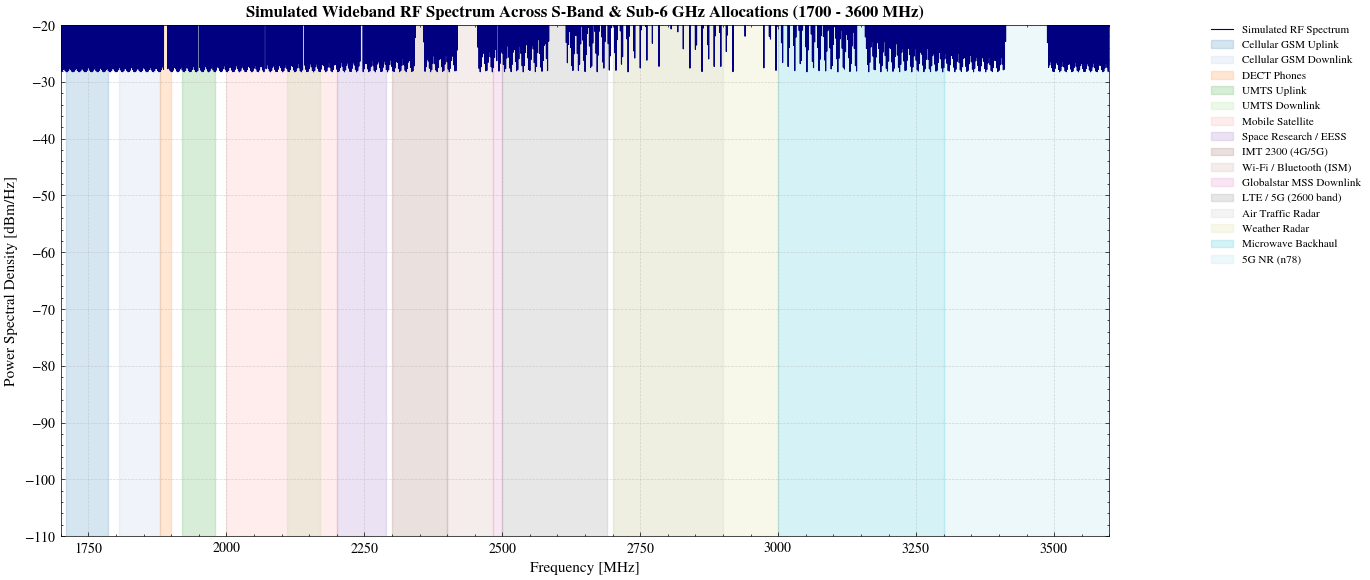

In [4]:

# -------------------------------------------------------------------
# Simulation Execution
# -------------------------------------------------------------------
# Frequency Grid: 1700 MHz to 3600 MHz with 0.02570 MHz resolution
f_start = 1700.0  # MHz
f_stop = 3600.0   # MHz
step = 0.0257  # MHz
freq_axis = np.arange(f_start, f_stop + (step/2), step)

# Baseline Noise Floor (-95 dBm)
noise_floor = np.random.normal(-95, 1.0, size=len(freq_axis))
full_spectrum_dB = noise_floor.copy()

# Add each RF source to the composite spectrum
for system_name, spec in rfi_specs.items():
    sig_pwr = generate_signal_shape(
        freq_axis,
        spec["f_c"],
        spec["obw"],
        spec["eta"],
        spec["type"],
        amplitude_dB=-40.0,
    )
    # Power addition in linear domain
    full_spectrum_dB = 10 * np.log10(
        10 ** (full_spectrum_dB / 10.0) + 10 ** (sig_pwr / 10.0)
    )

# -------------------------------------------------------------------
# Plot Wideband Composite Spectrum
# -------------------------------------------------------------------
plt.figure(figsize=(14, 6))
plt.plot(freq_axis, full_spectrum_dB, color="navy", lw=0.8, label="Simulated RF Spectrum")

# Highlight bands
colors = plt.cm.tab20(np.linspace(0, 1, len(rfi_specs)))
for idx, (name, spec) in enumerate(rfi_specs.items()):
    f1, f2 = spec["band"]
    plt.axvspan(f1, f2, color=colors[idx], alpha=0.18, label=f"{name}")

plt.title(
    "Simulated Wideband RF Spectrum Across S-Band & Sub-6 GHz Allocations (1700 - 3600 MHz)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Frequency [MHz]", fontsize=11)
plt.ylabel("Power Spectral Density [dBm/Hz]", fontsize=11)
plt.ylim(-110, -20)
plt.xlim(1700, 3600)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right", bbox_to_anchor=(1.25, 1.02), fontsize=8)
plt.tight_layout()
plt.show()

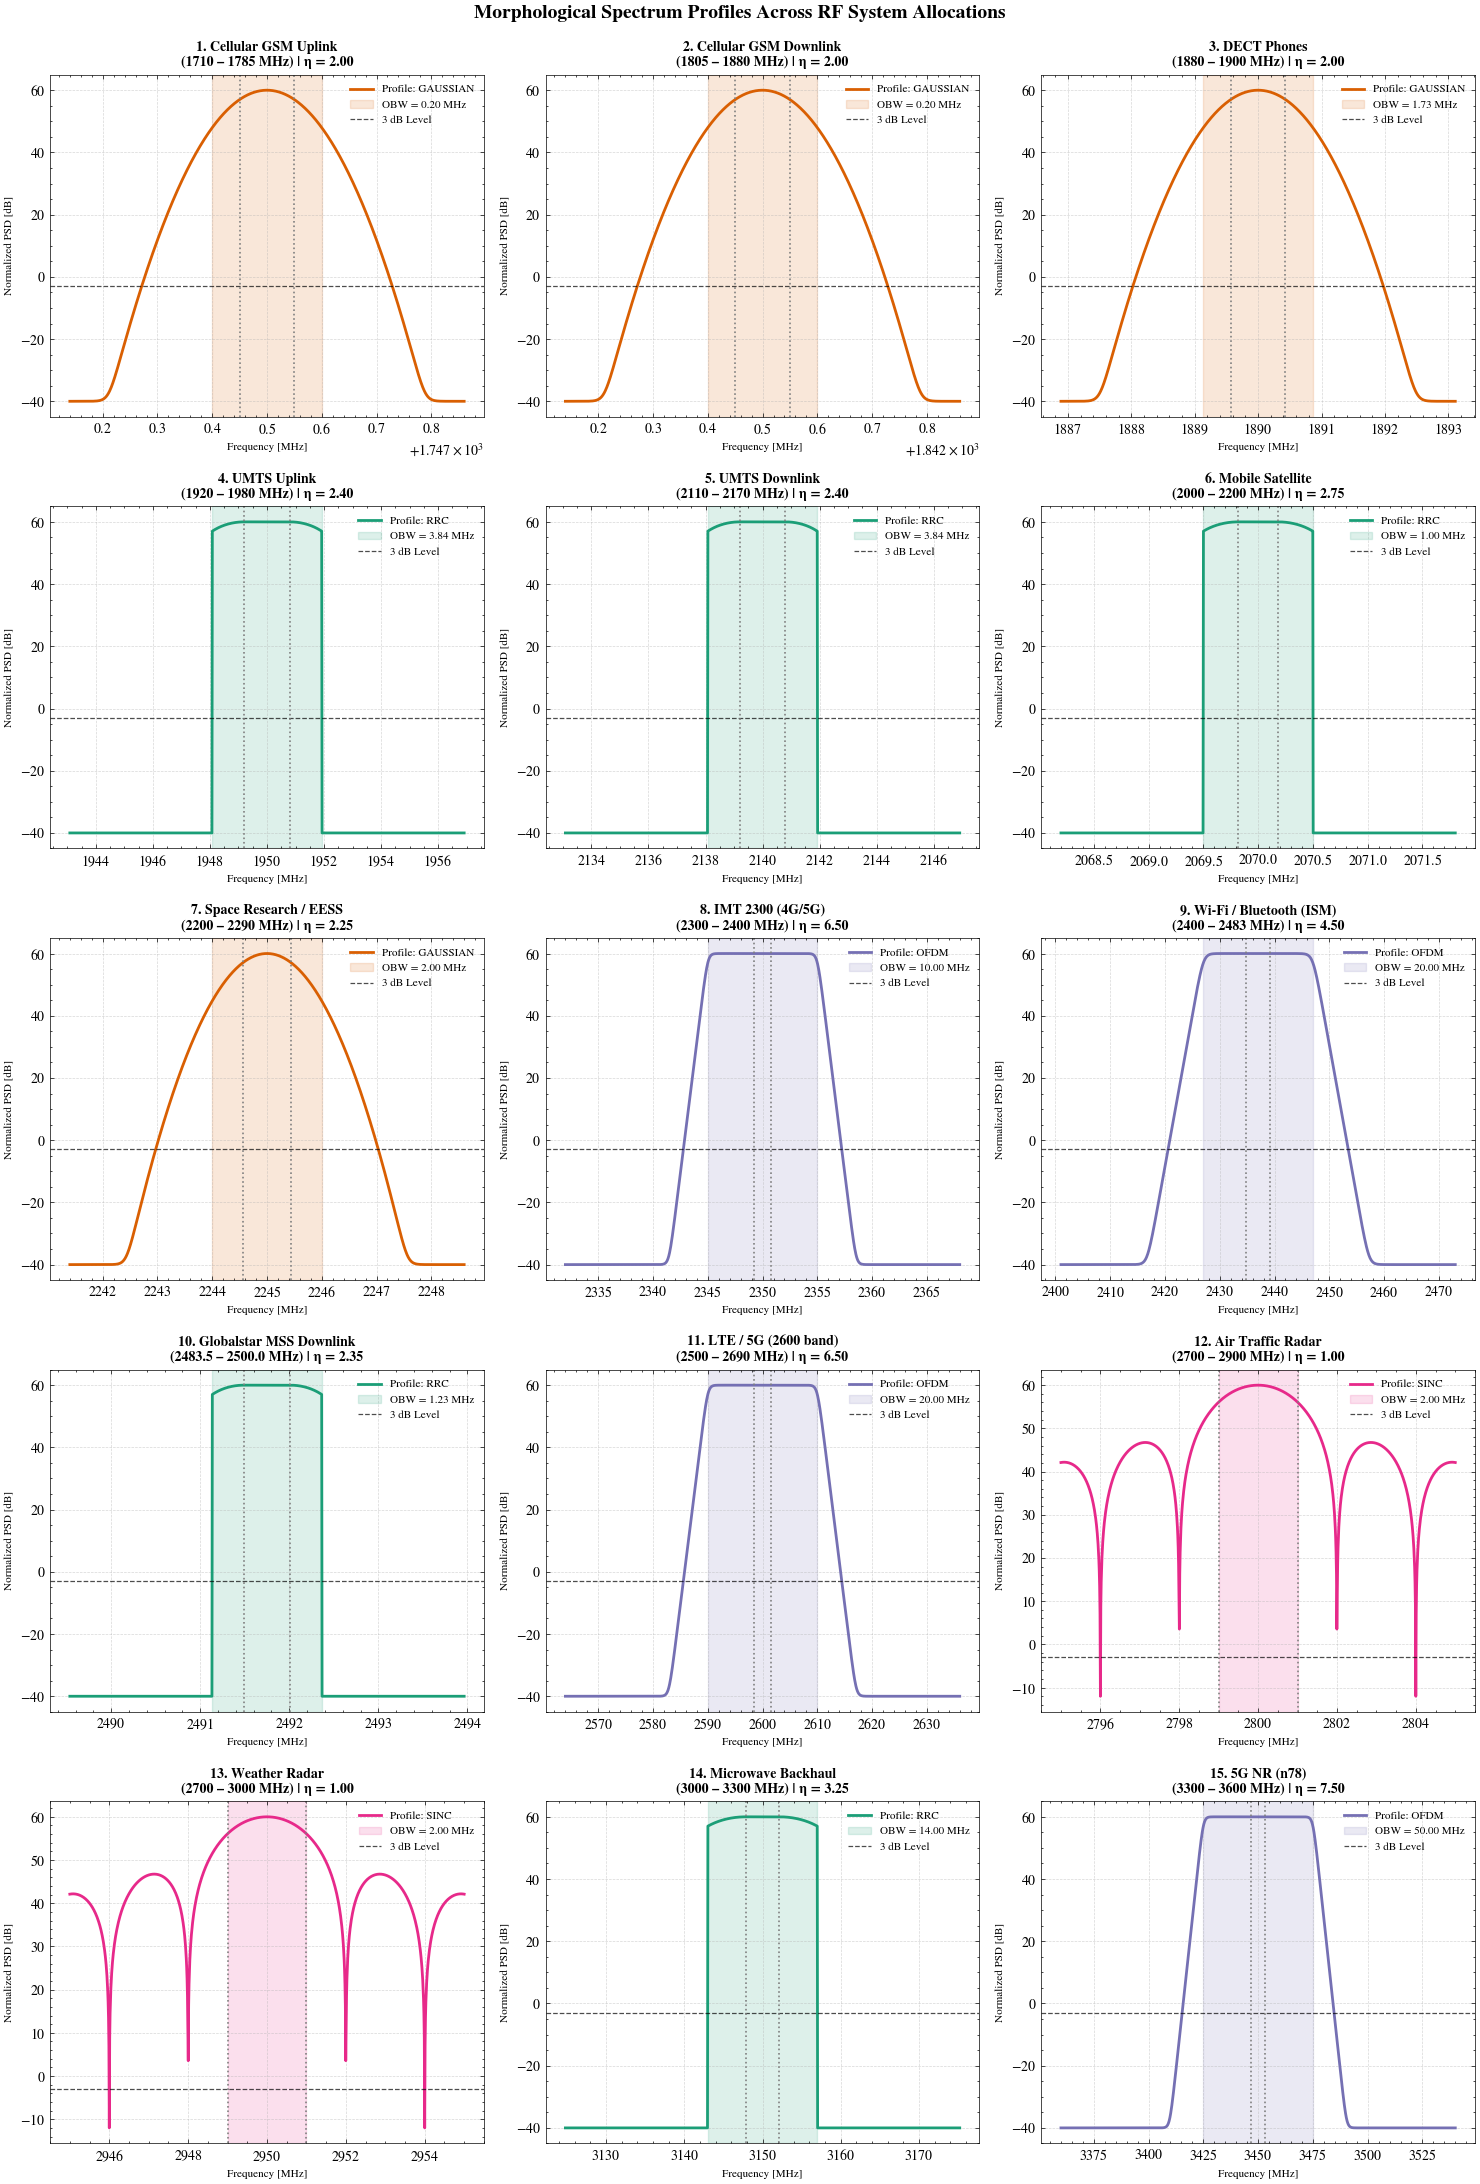

In [5]:
# -------------------------------------------------------------------
# Multi-Panel Grid Plotting (8 Rows x 2 Columns)
# -------------------------------------------------------------------
fig, axes = plt.subplots(5, 3, figsize=(15, 22))
axes = axes.flatten()

# Color mapping by morphological family
type_colors = {
    "gaussian": "#d95f02",  # Orange/Brown for Peaked signals
    "rrc": "#1b9e77",  # Teal/Green for Raised Cosine
    "ofdm": "#7570b3",  # Purple for Flat-Top OFDM
    "sinc": "#e7298a",  # Pink/Red for Radar Sinc
}

for idx, (name, spec) in enumerate(rfi_specs.items()):
    ax = axes[idx]
    f_c = spec["f_c"]
    obw = spec["obw"]
    eta = spec["eta"]
    sig_type = spec["type"]
    fwhm = obw / eta

    # Create localized frequency axis around channel center
    span = max(obw * 1.8, fwhm * 2.5)
    f_axis = np.linspace(f_c - span, f_c + span, 1000)

    # Generate PSD profile
    psd_dB = generate_signal_shape(f_axis, f_c, obw, eta, sig_type)

    # Plot Spectrum Line
    line_color = type_colors.get(sig_type, "blue")
    ax.plot(
        f_axis,
        psd_dB,
        color=line_color,
        lw=2.0,
        label=f"Profile: {sig_type.upper()}",
    )

    # Highlight Occupied Bandwidth (99% OBW)
    ax.axvspan(
        f_c - obw / 2.0,
        f_c + obw / 2.0,
        color=line_color,
        alpha=0.15,
        label=f"OBW = {obw:.2f} MHz",
    )

    # Mark Full Width at Half Maximum (-3 dB level)
    ax.axhline(
        -3.0,
        color="black",
        linestyle="--",
        linewidth=0.9,
        alpha=0.7,
        label="3 dB Level",
    )
    ax.axvline(f_c - fwhm / 2.0, color="gray", linestyle=":", linewidth=1.2)
    ax.axvline(f_c + fwhm / 2.0, color="gray", linestyle=":", linewidth=1.2)

    # Subplot Formatting & Annotations
    ax.set_title(
        f"{idx+1}. {name}\n({spec['band'][0]} – {spec['band'][1]} MHz) | η = {eta:.2f}",
        fontsize=10,
        fontweight="bold",
    )
    ax.set_xlabel("Frequency [MHz]", fontsize=8)
    ax.set_ylabel("Normalized PSD [dB]", fontsize=8)
    #ax.set_ylim(-40, 3)
    #ax.set_xlim(f_c - span, f_c + span)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right", fontsize=8)

plt.suptitle(
    "Morphological Spectrum Profiles Across RF System Allocations",
    fontsize=14,
    fontweight="bold",
    y=0.995,
)
plt.tight_layout()
plt.show()

# Lets overleay the simulated signal oon the peaks identified

In [6]:
# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline




# quantify the outliers
def quantify_all_outliers(freq, power, peak_freqs, 
                           threshold=0.05, 
                           plot=True):
    """
    Quantify frequency range affected by each detected outlier.

    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum).
    power : 1D array
        Detrended power spectrum at ONE time step.
    peak_freqs : list
        List of detected outlier peak frequencies (GHz).
    threshold : float
        Reference level to define rise/set.
    plot : bool
        If True, produce one plot per outlier.

    Returns
    -------
    results : list of dict
        One dictionary per outlier.
    """

    freq = np.asarray(freq)
    power = np.asarray(power)
    df = np.abs(freq[1] - freq[0])

    results_outliers = []

    for i, peak_f in enumerate(peak_freqs):

        # -------------------------------------------------
        # 1) Find closest index to detected peak frequency
        # -------------------------------------------------
        peak_index = np.argmin(np.abs(freq - peak_f))

        # -------------------------------------------------
        # 2) Walk LEFT until below threshold
        # -------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1

        start_freq = freq[left_index]

        # -------------------------------------------------
        # 3) Walk RIGHT until below threshold
        # -------------------------------------------------
        right_index = peak_index
        while right_index < len(power)-1 and power[right_index] > threshold:
            right_index += 1

        end_freq = freq[right_index]

        # -------------------------------------------------
        # 4) Compute bandwidth & channels
        # -------------------------------------------------
        bandwidth = end_freq - start_freq
        n_channels = int(np.round(bandwidth / df))

        peak_power = power[peak_index]

        result = {
            "peak_freq": freq[peak_index],
            "peak_power": peak_power,
            "start_freq": start_freq,
            "end_freq": end_freq,
            "bandwidth": bandwidth,
            "n_channels": n_channels,
        
            
        }

        results_outliers.append(result)

        # Print results
        print(f"\nOutlier {i+1}:")
        print(f"  Peak Frequency : {freq[peak_index]:.4f} GHz")
        print(f"  Peak Power     : {peak_power:.4f} dB")
        print(f"  Start Frequency: {start_freq:.4f} GHz")
        print(f"  End Frequency  : {end_freq:.4f} GHz")
        print(f"  Bandwidth      : {bandwidth:.4f} GHz")
        print(f"  Corrupted Ch.  : {n_channels} channels")

        # -------------------------------------------------
        # 5) Plot individual outlier
        # -------------------------------------------------
        if plot:
            # Add small padding for visualization
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq)-1)

            plt.figure(figsize=(10,6))
            plt.plot(freq[lo:hi], power[lo:hi], '.', color='steelblue')
            plt.axvline(start_freq, color='green', linestyle='--', label='Start')
            plt.axvline(freq[peak_index], color='red', linestyle='-', label='Peak')
            plt.axvline(end_freq, color='orange', linestyle='--', label='End')
            plt.axhline(threshold, linestyle=':', color='black', label='Threshold = 0.05 dB')
            plt.xlabel("Frequency [GHz]", fontsize=17)
            plt.ylabel("Detrended Power [log(dB)]", fontsize=17)
            plt.title(f"Outlier {i+1} at {freq[peak_index]:.4f} GHz")
            plt.grid(True, linestyle='--', alpha=0.6)
            plt.legend(fontsize=12)
            # plt.show()


    return results_outliers



def build_rfi_mask(freq, results_outliers):
    """
    Create boolean mask for RFI contaminated channels.

    Returns:
        mask : True = flagged (RFI)
    """
    mask = np.zeros(len(freq), dtype=bool)

    for res in results_outliers:
        start = res["start_freq"]
        end = res["end_freq"]

        # Flag all frequencies inside range
        mask |= (freq >= start) & (freq <= end)

    return mask





def analyse_rfi(freq, power, peak_freqs,
                 threshold=0.05,
                 plot=True):
    """
    Characterise each detected RFI outlier in a single-time-step spectrum.
 
    For every frequency listed in `peak_freqs`, this computes two
    complementary bandwidth estimates:
 
    1. Threshold-crossing bandwidth: the extent (in frequency) over which
       the detrended power stays above a fixed absolute `threshold`,
       measured by walking outward from the peak until the power drops
       below that level. This is useful for counting how many channels
       are contaminated above your flagging threshold.
 
    2. FWHM (Full Width at Half Maximum): the width of the peak at half
       its prominence above the local baseline, computed via
       `scipy.signal.peak_widths` with `rel_height=0.5`. This is the
       standard spectral-linewidth definition and is directly comparable
       to known service channel bandwidths (e.g. ~200 kHz for GSM).
 
    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum), in MHz.
    power : 1D array
        Detrended/baseline-corrected power spectrum at ONE time step
        (linear power, not dB).
    peak_freqs : list or 1D array
        Frequencies (MHz) of detected outlier peaks.
    threshold : float
        Absolute power level used to define the rise/fall crossing for
        the threshold-based bandwidth (metric 1 above).
    plot : bool
        If True, produce one diagnostic plot per outlier.
    save_dir : str or None
        If given, save each plot as PNG/PDF into this directory.
        If None, plots are shown but not saved.
 
    Returns
    -------
    results : list of dict
        One dictionary per outlier, containing both bandwidth estimates,
        peak frequency/power, and the number of contaminated channels.
    """
 
    freq = np.asarray(freq)
    power = np.asarray(power)
    freq_resolution = freq[1] - freq[0]
 
    # -----------------------------------------------------------------
    # Convert peak frequencies -> nearest array indices (needed for
    # peak_widths, which operates on integer index positions)
    # -----------------------------------------------------------------
    peak_indices = np.array(
        [np.argmin(np.abs(freq - pf)) for pf in peak_freqs]
    )
 
    # -----------------------------------------------------------------
    # FWHM for ALL peaks at once (vectorised call, rel_height=0.5 =>
    # half-maximum relative to each peak's own prominence)
    # -----------------------------------------------------------------
    widths_idx, width_heights, left_ips, right_ips = peak_widths(
        power, peak_indices, rel_height=0.5
    )
    fwhm_freq = widths_idx * freq_resolution
 
    # -----------------------------------------------------------------
    # Sanity check: a zero-width / zero-prominence result means the
    # supplied peak_freqs did not line up with a true local maximum in
    # `power` (e.g. peak_freqs came from a different array/step than
    # the one passed in here). Warn loudly rather than silently
    # returning a meaningless FWHM of 0.
    # -----------------------------------------------------------------
    # for i, w in enumerate(widths_idx):
    #     if w == 0:
    #         warnings.warn(
    #             f"Peak at {peak_freqs[i]:.4f} MHz has zero FWHM/prominence. "
    #             "This usually means peak_freqs was not derived from "
    #             "find_peaks(power, ...) on this same array. Pass the "
    #             "find_peaks indices/frequencies directly to avoid this.",
    #             RuntimeWarning,
    #         )
 
    idx_axis = np.arange(len(freq))
    fwhm_left_freq = np.interp(left_ips, idx_axis, freq)
    fwhm_right_freq = np.interp(right_ips, idx_axis, freq)
 
    results = []
 
    for i, peak_f in enumerate(peak_freqs):
 
        peak_index = peak_indices[i]
        peak_power = power[peak_index]
 
        # ---------------------------------------------------------
        # Threshold-crossing bandwidth (manual walk, absolute level)
        # ---------------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1
        start_freq = freq[left_index]
 
        right_index = peak_index
        while right_index < len(power) - 1 and power[right_index] > threshold:
            right_index += 1
        end_freq = freq[right_index]
 
        bandwidth = end_freq - start_freq
        n_channels = right_index - left_index + 1
 
        # ---------------------------------------------------------
        # Collect results
        # ---------------------------------------------------------
        result = {
            "peak_freq_mhz": freq[peak_index],
            "peak_power": peak_power,
            "threshold_start_freq_mhz": start_freq,
            "threshold_end_freq_mhz": end_freq,
            "threshold_bandwidth_mhz": bandwidth,
            "n_channels_above_threshold": n_channels,
            "fwhm_mhz": fwhm_freq[i],
            "fwhm_khz": fwhm_freq[i] * 1e3,
            "fwhm_left_freq_mhz": fwhm_left_freq[i],
            "fwhm_right_freq_mhz": fwhm_right_freq[i],
            "fwhm_half_max_power": width_heights[i],
        }
        results.append(result)
 
        print(f"\nOutlier {i + 1}:")
        print(f"  Peak Frequency        : {result['peak_freq_mhz']:.4f} MHz")
        print(f"  Peak Power            : {result['peak_power']:.4f}")
        print(f"  Threshold Start Freq  : {start_freq:.4f} MHz")
        print(f"  Threshold End Freq    : {end_freq:.4f} MHz")
        print(f"  Threshold Bandwidth   : {bandwidth * 1e3:.2f} kHz")
        print(f"  Channels > threshold  : {n_channels}")
        print(f"  FWHM                  : {result['fwhm_khz']:.2f} kHz")
 
        # ---------------------------------------------------------
        # Plot (one figure per outlier, zoomed around the peak)
        # ---------------------------------------------------------
        if plot:
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq) - 1)
 
            fig, ax = plt.subplots(figsize=(9, 5))
 
            ax.plot(freq[lo:hi], power[lo:hi], color="steelblue", lw=1,
                    label="Spectrum")
            ax.plot(freq[peak_index], power[peak_index], "rx", ms=8, mew=2,
                    label="Detected peak")
 
            # FWHM span (half-max, from peak_widths)
            ax.hlines(
                width_heights[i], fwhm_left_freq[i], fwhm_right_freq[i],
                color="darkorange", lw=2, label="FWHM (half-max)"
            )
            ax.vlines(
                [fwhm_left_freq[i], fwhm_right_freq[i]],
                ymin=power[lo:hi].min(), ymax=width_heights[i],
                color="gray", linestyle="--", lw=0.8
            )
 
            # Threshold-crossing span (absolute level)
            ax.axhline(threshold, color="green", linestyle=":", lw=1,
                       label=f"Threshold = {threshold}")
            ax.axvline(start_freq, color="green", linestyle=":", lw=0.8)
            ax.axvline(end_freq, color="green", linestyle=":", lw=0.8)
 
            ax.annotate(
                f"FWHM = {result['fwhm_khz']:.1f} kHz",
                xy=(freq[peak_index], power[peak_index]),
                xytext=(freq[peak_index], power[peak_index] * 1.15),
                ha="center", fontsize=9,
                arrowprops=dict(arrowstyle="->", color="black", lw=0.8)
            )
 
            ax.set_xlabel("Frequency (MHz)")
            ax.set_ylabel("Power (linear)")
            ax.set_title(f"Outlier {i + 1} at {freq[peak_index]:.4f} MHz")
            ax.legend(loc="upper right", fontsize=8)
            ax.grid(alpha=0.3)
            fig.tight_layout()
 
            # if save_dir is not None:
            #     fig.savefig(
            #         f"{save_dir}/outlier_{i + 1}_at_{freq[peak_index]:.4f}MHz.png",
            #         dpi=300, bbox_inches="tight"
            #     )
            #     fig.savefig(
            #         f"{save_dir}/outlier_{i + 1}_at_{freq[peak_index]:.4f}MHz.pdf",
            #         dpi=300, bbox_inches="tight"
            #     )
            # plt.close(fig)
 
    return results

# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [7]:
# DATA
filename = "EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = True  # Set to True to save the plots, False to just display them


In [8]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e6 # MHz
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]
        ra = f[f"{g}/ra"][30:]
        dec = f[f"{g}/dec"][30:]
        elevation = f[f"{g}/elevation"][30:]
        azimuth = f[f"{g}/azimuth"][30:]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum)},
            coords={"time": time, "frequency": frequency, "integration_time": integration_time, "ra": ra, "dec": dec, "elevation": elevation, "azimuth": azimuth}
        )

        datasets[g] = ds

In [9]:
# select a scan
scan = 'scan/000/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 163MB
Dimensions:           (time: 634, frequency: 63877, integration_time: 634,
                       ra: 634, dec: 634, elevation: 634, azimuth: 634)
Coordinates:
  * time              (time) float64 5kB 1.691e+09 1.691e+09 ... 1.691e+09
  * frequency         (frequency) float64 511kB 1.793e+03 ... 3.498e+03
  * integration_time  (integration_time) float64 5kB 0.1142 0.1159 ... 0.1141
  * ra                (ra) float64 5kB 293.8 293.8 293.8 ... 296.0 296.0 296.0
  * dec               (dec) float64 5kB -62.32 -62.33 -62.33 ... -65.13 -65.14
  * elevation         (elevation) float64 5kB 26.87 26.87 26.87 ... 26.87 26.87
  * azimuth           (azimuth) float64 5kB 148.6 148.6 148.6 ... 151.8 151.8
Data variables:
    spectrum          (time, frequency) float32 162MB 1.926e+11 ... 4.099e+09

In [10]:
# define the variables
spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra / integration_time[:, np.newaxis]
frequency_mhz = data['frequency'].values 
time = data['time'].values
elevation = data['elevation'].values
azimuth = data['azimuth'].values



# Spectrum to dB
spectrum_db = 10*np.log10(spectrum**2)
mean_spectrum_db = np.mean(spectrum_db, axis=0)


# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)


In [11]:
# perfom the time average and peak ideintification

spectrum_corrected = base_correction(frequency_mhz, mean_spectrum_db)

# Peak detection

sigma_value_high = 3
    # Detect peaks
threshold = MAD(spectrum_corrected) + sigma_value_high * np.std(spectrum_corrected)
peaks, properties = find_peaks(spectrum_corrected,
                                height=threshold,
                                prominence=0.5,
                                distance=80
                                )

In [12]:
# define the FWHM

widths_idx, width_heights, left_ips, right_ips = peak_widths(
    spectrum_corrected, peaks, rel_height=0.5)

# frequency resolution
freq_resolution = frequency_mhz[1] - frequency_mhz[0]
fwhm_freq = widths_idx * freq_resolution



for i, pk in enumerate(peaks):
    print(f"Peak at {frequency_mhz[pk]:.4f} MHz | FWHM = {fwhm_freq[i]:.4f} MHz "
          f"| half-max level = {width_heights[i]:.4e}")

Peak at 1819.7346 MHz | FWHM = 0.5769 MHz | half-max level = 4.2726e+00
Peak at 2002.9163 MHz | FWHM = 0.9039 MHz | half-max level = 6.4020e+00
Peak at 2170.3434 MHz | FWHM = 0.0350 MHz | half-max level = 7.1430e-01
Peak at 2184.1488 MHz | FWHM = 0.0365 MHz | half-max level = 6.9554e-01
Peak at 2200.0637 MHz | FWHM = 0.8973 MHz | half-max level = 5.3977e+00
Peak at 2362.9780 MHz | FWHM = 1.9097 MHz | half-max level = 6.3782e-01


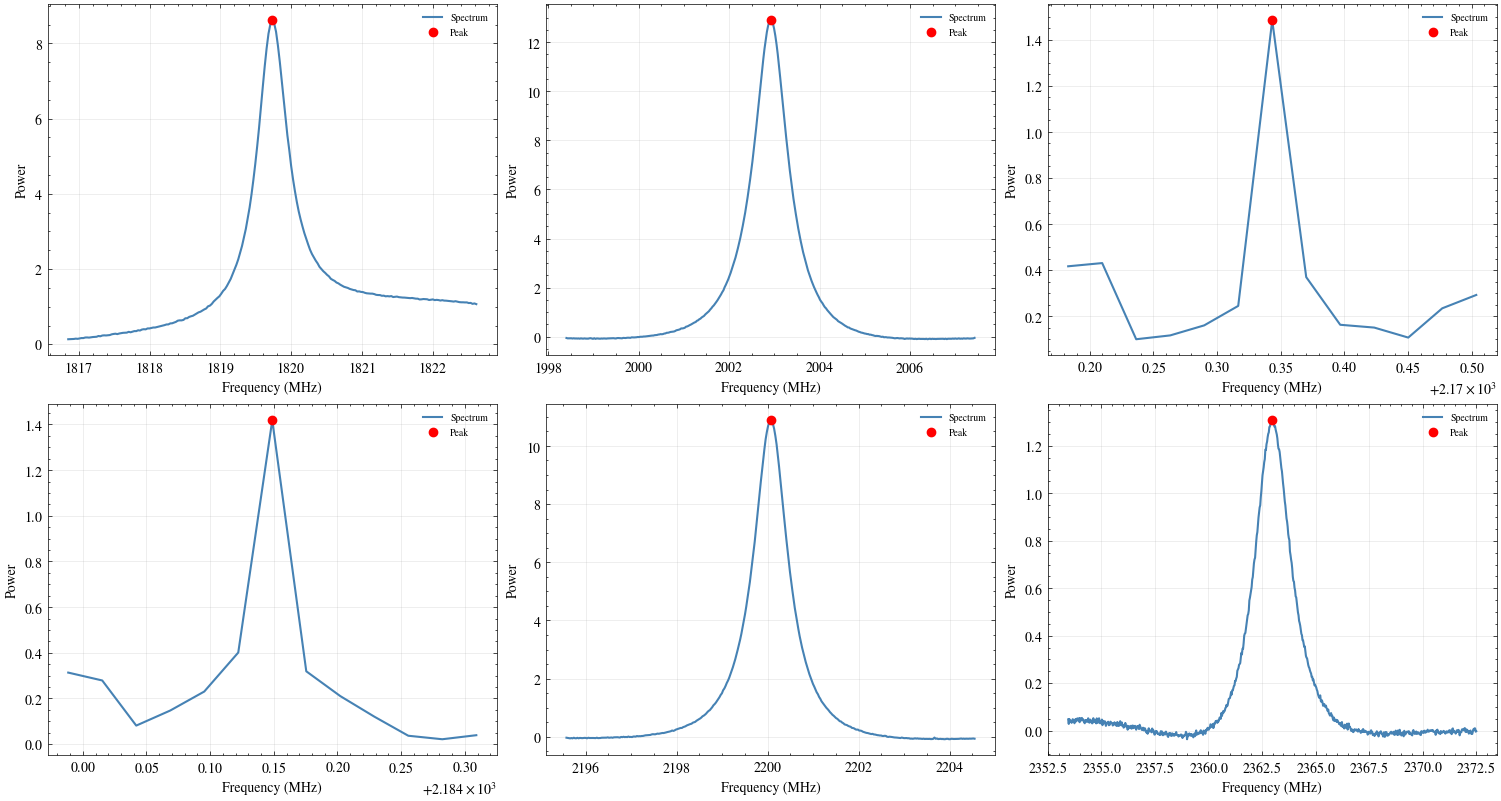

In [13]:

 
# ---------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side of the peak
 
n_peaks = len(peaks)
 
ncols = 3
nrows = math.ceil(n_peaks / ncols)
 
fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5 * ncols, 4 * nrows),
    constrained_layout=True
)
 
axes = np.atleast_1d(axes).flatten()
 
gaussian_fit_results = []  # collect fit params + R^2 per peak
 
for i, peak in enumerate(peaks):
 
    ax = axes[i]

    centre = frequency_mhz[peak]

    # Zoom window proportional to the measured FWHM
    x_min = centre - window * fwhm_freq[i]
    x_max = centre + window * fwhm_freq[i]

    mask = (frequency_mhz >= x_min) & (frequency_mhz <= x_max)

    x_data = frequency_mhz[mask]
    y_data = spectrum_corrected[mask]

    
    # -------------------------------------------------------
    # Spectrum
    # -------------------------------------------------------
    ax.plot(
        x_data,
        y_data,
        color="steelblue",
        lw=1.5,
        label="Spectrum"
    )
 
    # Peak marker
    ax.plot(
        centre,
        spectrum_corrected[peak],
        'ro',
        ms=6,
        label='Peak'
    )
 
 
    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Power")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper right")


plt.show()
 

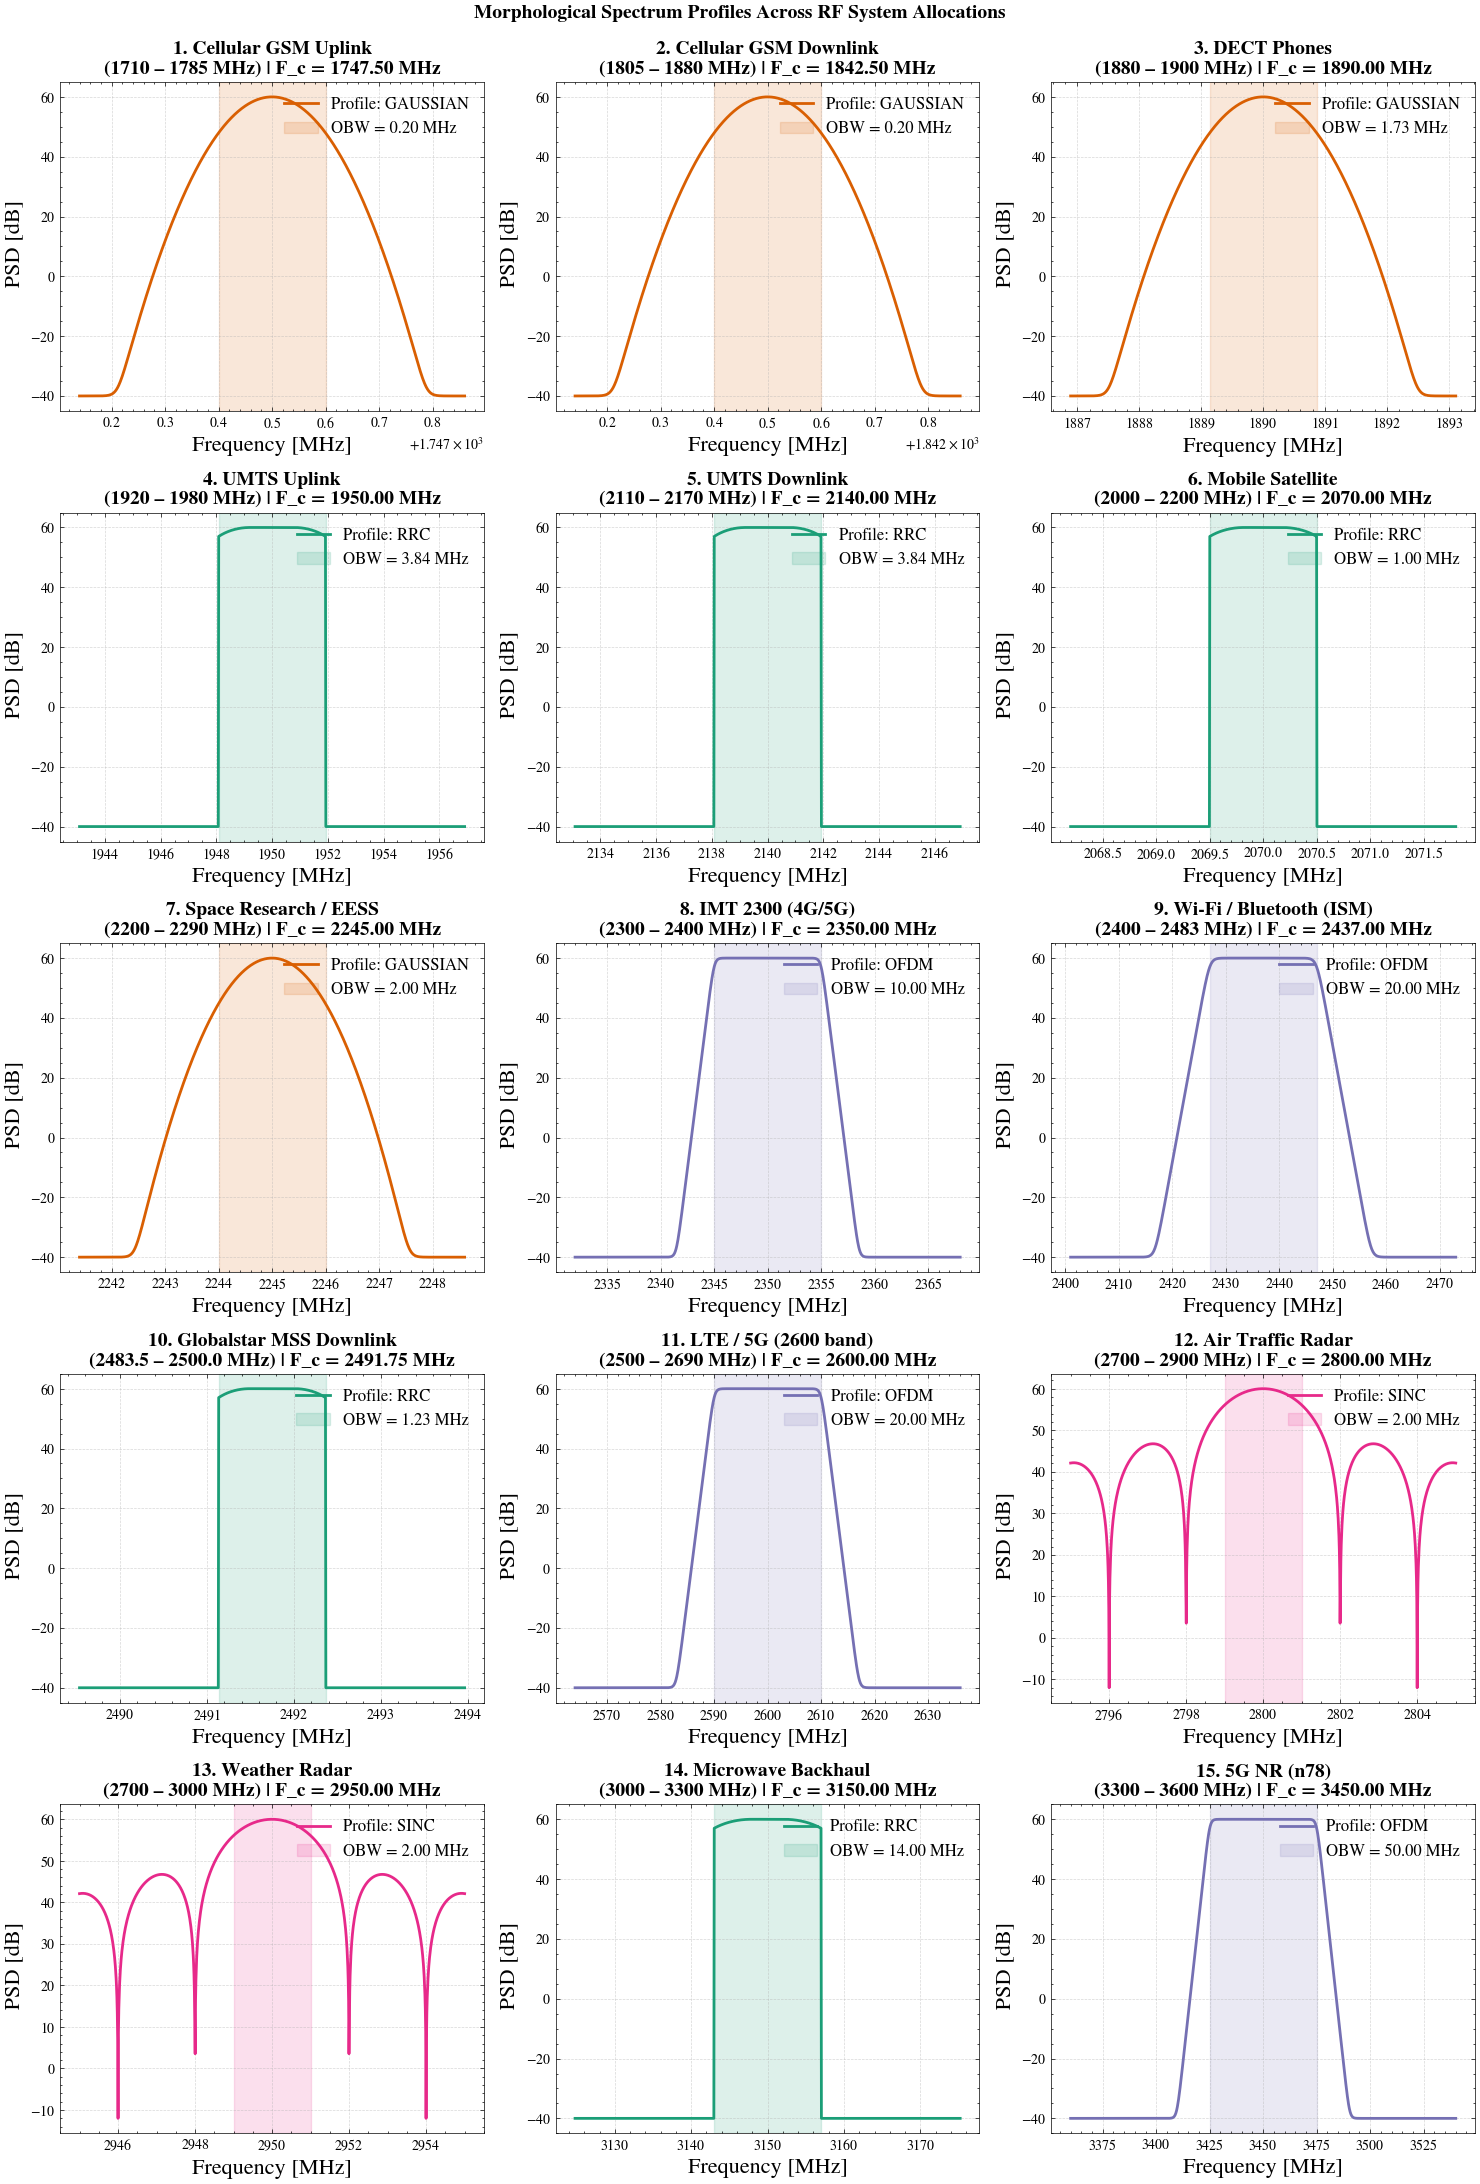

In [14]:
# -------------------------------------------------------------------
# Multi-Panel Grid Plotting (7 Rows x 2 Columns)
# -------------------------------------------------------------------
fig, axes = plt.subplots(5, 3, figsize=(15, 22))
axes = axes.flatten()

# # Color mapping by morphological family
# type_colors = {
#     "gaussian": "#d95f02",  # Orange/Brown for Peaked signals
#     "rrc": "#1b9e77",  # Teal/Green for Raised Cosine
#     "ofdm": "#7570b3",  # Purple for Flat-Top OFDM
#     "sinc": "#e7298a",  # Pink/Red for Radar Sinc
# }

for idx, (name, spec) in enumerate(rfi_specs.items()):
    ax = axes[idx]
    f_c = spec["f_c"]
    obw = spec["obw"]
    eta = spec["eta"]
    sig_type = spec["type"]
    fwhm = obw / eta

    # Create localized frequency axis around channel center
    span = max(obw * 1.8, fwhm * 2.5)
    f_axis = np.linspace(f_c - span, f_c + span, 1000)

    # Generate PSD profile
    psd_dB = generate_signal_shape(f_axis, f_c, obw, eta, sig_type)

    # Plot Spectrum Line
    line_color = type_colors.get(sig_type, "blue")
    ax.plot(
        f_axis,
        psd_dB,
        color=line_color,
        lw=2.0,
        label=f"Profile: {sig_type.upper()}",
    )

    # Highlight Occupied Bandwidth (99% OBW)
    ax.axvspan(
        f_c - obw / 2.0,
        f_c + obw / 2.0,
        color=line_color,
        alpha=0.15,
        label=f"OBW = {obw:.2f} MHz",
    )

    # Mark Full Width at Half Maximum (-3 dB level)
    # ax.axhline(
    #     -3.0,
    #     color="black",
    #     linestyle="--",
    #     linewidth=0.9,
    #     alpha=0.7,
    #     label="3 dB Level",
    # )
    # ax.axvline(f_c - fwhm / 2.0, color="gray", linestyle=":", linewidth=1.2)
    # ax.axvline(f_c + fwhm / 2.0, color="gray", linestyle=":", linewidth=1.2)

    # Subplot Formatting & Annotations
    ax.set_title(
        f"{idx+1}. {name}\n({spec['band'][0]} – {spec['band'][1]} MHz) | F_c = {f_c:.2f} MHz",
        fontsize=14,
        fontweight="bold",
    )
    ax.set_xlabel("Frequency [MHz]", fontsize=16)
    ax.set_ylabel(" PSD [dB]", fontsize=16)
    #ax.set_ylim(-40, 3)
    #ax.set_xlim(f_c - span, f_c + span)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right", fontsize=12)

plt.suptitle(
    "Morphological Spectrum Profiles Across RF System Allocations",
    fontsize=14,
    fontweight="bold",
    y=0.995,
)
plt.tight_layout()
plt.show()

# overlay the plots

In [15]:


def simulate_normalized_shape(
    f_axis, f_center, obw_nom, eta_nom, shape_type="gaussian"
):
    """Generates a normalized reference profile [0, 1] centered at f_center."""
    fwhm_nom = obw_nom / eta_nom
    dev = np.abs(f_axis - f_center)

    if shape_type == "gaussian":
        sigma = fwhm_nom / (2 * np.sqrt(2 * np.log(2)))
        p_shape = np.exp(-0.5 * (dev / sigma) ** 2)

    elif shape_type == "rrc":
        f_pass = fwhm_nom / 2.0
        f_stop = obw_nom / 2.0
        p_shape = np.where(
            dev <= f_pass,
            1.0,
            np.where(
                dev <= f_stop,
                0.5
                * (
                    1
                    + np.cos(
                        np.pi * (dev - f_pass) / (2 * (f_stop - f_pass) + 1e-6)
                    )
                ),
                0.0,
            ),
        )

    elif shape_type == "ofdm":
        half_obw = obw_nom / 2.0
        edge_steepness = 12.0 / fwhm_nom
        p_shape = 1.0 / (1.0 + np.exp(edge_steepness * (dev - half_obw)))

    elif shape_type == "sinc":
        x = np.pi * (f_axis - f_center) / (fwhm_nom + 1e-6)
        p_shape = np.sinc(x / np.pi) ** 2
    else:
        p_shape = np.exp(-0.5 * (dev / (fwhm_nom / 2.355)) ** 2)

    return p_shape


def find_matching_system(f_center):
    """Finds candidate system from catalog matching frequency center."""
    for sys_name, specs in rfi_specs.items():
        f_start, f_stop = specs["band"]
        if f_start <= f_center <= f_stop:
            return sys_name, specs
    return "Unknown / Unlicensed", None



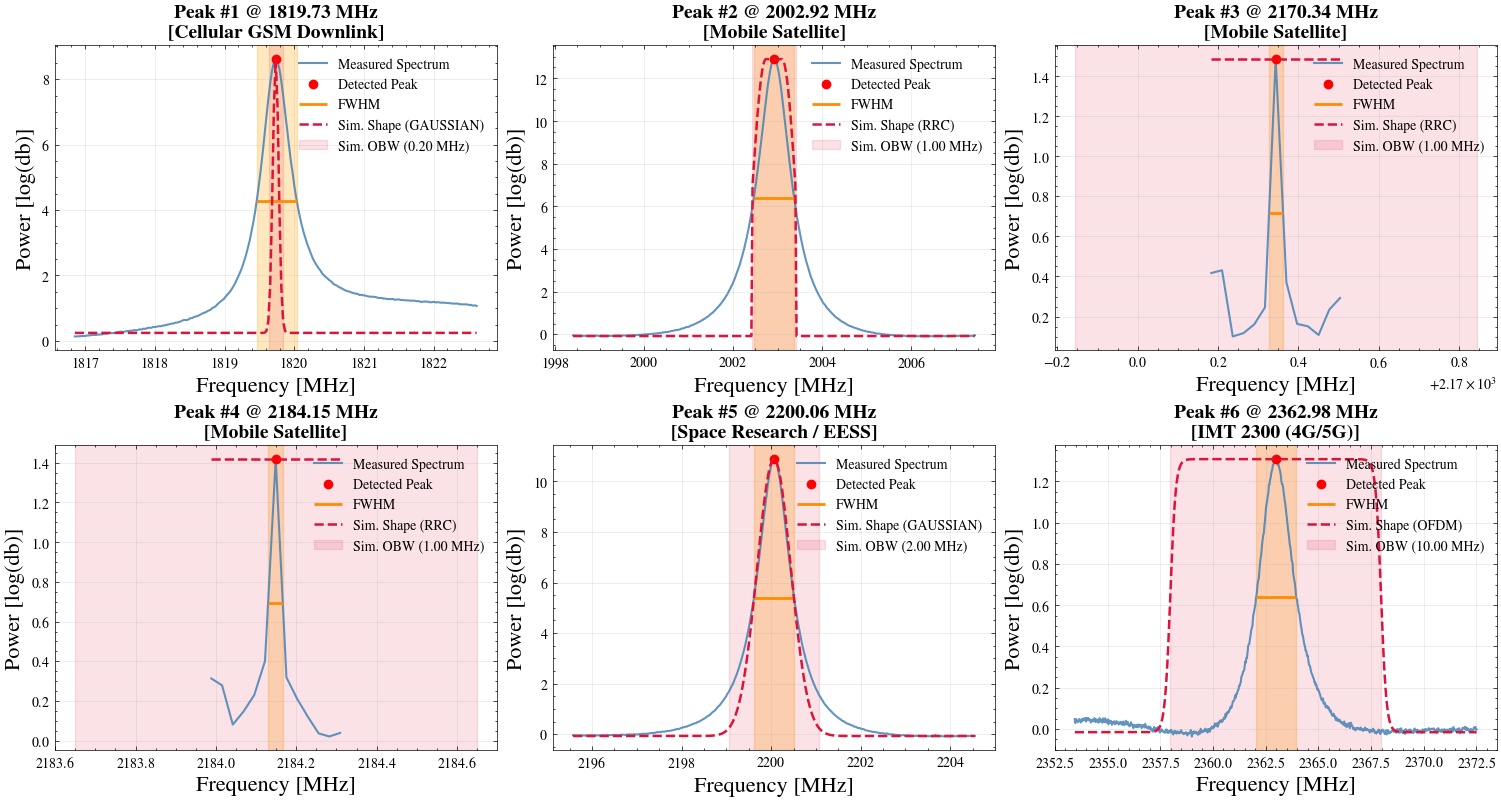

In [16]:

 
# Convert fractional index crossings to frequency values
idx_axis = np.arange(len(frequency_mhz))
left_freq = np.interp(left_ips, idx_axis, frequency_mhz)
right_freq = np.interp(right_ips, idx_axis, frequency_mhz)

# -------------------------------------------------------------------
# 2. Comparative Peak Visualization Loop
# -------------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side
n_peaks = len(peaks)

ncols = 3
nrows = math.ceil(n_peaks / ncols)

fig, axes = plt.subplots(
    nrows, ncols, figsize=(5 * ncols, 4 * nrows), constrained_layout=True
)

axes = np.atleast_1d(axes).flatten()

for i, peak in enumerate(peaks):
    ax = axes[i]
    centre = frequency_mhz[peak]
    fwhm_val = fwhm_freq[i]

    # Zoom window proportional to measured FWHM
    x_min = centre - window * fwhm_val
    x_max = centre + window * fwhm_val

    mask = (frequency_mhz >= x_min) & (frequency_mhz <= x_max)
    x_data = frequency_mhz[mask]
    y_data = spectrum_corrected[mask]

    # 1. Plot Measured Spectrum
    ax.plot(
        x_data,
        y_data,
        color="steelblue",
        lw=1.5,
        alpha=0.85,
        label="Measured Spectrum",
    )
    # Spectrum
    peak_amplitude = spectrum_corrected[peak]
    ax.plot(centre, peak_amplitude, "ro", ms=6, label="Detected Peak")

        # FWHM line
    ax.hlines(
        width_heights[i],
        left_freq[i],
        right_freq[i],
        color='darkorange',
        lw=2,
        label='FWHM'
    )

       # Shade the FWHM
    ax.axvspan(
        left_freq[i],
        right_freq[i],
        color='orange',
        alpha=0.25
    )

    # 3. Lookup & Generate Simulated Target Signal Overlay
    sys_name, sys_specs = find_matching_system(centre)

    if sys_specs is not None:
        obw_nom = sys_specs["obw"]
        eta_nom = sys_specs["eta"]
        shape_type = sys_specs["type"]
    else:
        # Fallback to measured metrics if outside catalog
        obw_nom = fwhm_val * 2.0
        eta_nom = 2.0
        shape_type = "gaussian"

    # Generate normalized shape profile
    sim_shape = simulate_normalized_shape(
        x_data, centre, obw_nom, eta_nom, shape_type
    )

    # Scale simulated signal to match measured peak amplitude and baseline noise floor
    baseline_noise = np.percentile(y_data, 10)
    y_simulated = baseline_noise + (peak_amplitude - baseline_noise) * sim_shape

    # 4. Plot Simulated Reference Signal
    ax.plot(
        x_data,
        y_simulated,
        color="crimson",
        linestyle="--",
        lw=1.8,
        label=f"Sim. Shape ({shape_type.upper()})",
    )

    # Shade Simulated Occupied Bandwidth (Crimson)
    ax.axvspan(
        centre - obw_nom / 2.0,
        centre + obw_nom / 2.0,
        color="crimson",
        alpha=0.12,
        label=f"Sim. OBW ({obw_nom:.2f} MHz)",
    )


    # Formatting and Annotations
    ax.set_title(
        f"Peak #{i+1} @ {centre:.2f} MHz\n[{sys_name}]",
        fontsize=14,
        fontweight="bold",
    )
    ax.set_xlabel("Frequency [MHz]", fontsize=16)
    ax.set_ylabel("Power [log(db)]", fontsize=16)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=10, loc="upper right")

# Hide extra empty subplots if grid size > n_peaks
for j in range(n_peaks, len(axes)):
    fig.delaxes(axes[j])




if to_save:
        # create full path
    full_path = os.path.join(dirname, scan_name)
    # create the directory if they don't exist
    os.makedirs(full_path, exist_ok=True)

    fig.savefig(
        os.path.join(full_path, f'{scan_name}_high_peak_signal_fits.png'),
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        os.path.join(full_path, f'{scan_name}_high_peak_signal_fits.pdf'),
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()

In [17]:
# flag the high level rfi
results_outliers = quantify_all_outliers(frequency_mhz, spectrum_corrected, frequency_mhz[peaks], plot=False)



Outlier 1:
  Peak Frequency : 1819.7346 GHz
  Peak Power     : 8.6135 dB
  Start Frequency: 1816.3433 GHz
  End Frequency  : 1827.3449 GHz
  Bandwidth      : 11.0016 GHz
  Corrupted Ch.  : 412 channels

Outlier 2:
  Peak Frequency : 2002.9163 GHz
  Peak Power     : 12.8918 dB
  Start Frequency: 2000.3262 GHz
  End Frequency  : 2005.2128 GHz
  Bandwidth      : 4.8866 GHz
  Corrupted Ch.  : 183 channels

Outlier 3:
  Peak Frequency : 2170.3434 GHz
  Peak Power     : 1.4836 dB
  Start Frequency: 2170.0764 GHz
  End Frequency  : 2177.4464 GHz
  Bandwidth      : 7.3700 GHz
  Corrupted Ch.  : 276 channels

Outlier 4:
  Peak Frequency : 2184.1488 GHz
  Peak Power     : 1.4184 dB
  Start Frequency: 2183.8284 GHz
  End Frequency  : 2184.2556 GHz
  Bandwidth      : 0.4272 GHz
  Corrupted Ch.  : 16 channels

Outlier 5:
  Peak Frequency : 2200.0637 GHz
  Peak Power     : 10.8794 dB
  Start Frequency: 2197.2866 GHz
  End Frequency  : 2202.4670 GHz
  Bandwidth      : 5.1804 GHz
  Corrupted Ch.  : 1

In [18]:
mask_high = build_rfi_mask(frequency_mhz, results_outliers)

# make a copy of the spectrum
mask_signal = spectrum_corrected.copy()

# replace the flagged channels with NaN
mask_signal = mask_signal[~mask_high]
mask_frequency = frequency_mhz[~mask_high]

 
sigma_value_low = 5 
threshold = MAD(mask_signal) + sigma_value_low * np.std(mask_signal)

peaks_low, properties = find_peaks(
    mask_signal,
    height=threshold,
    prominence=0.3,
    distance=110
)


In [19]:
# analyse low level peaks
# define the FWHM

widths_idx_low, width_heights_low, left_ips_low, right_ips_low = peak_widths(
    mask_signal,peaks_low , rel_height=0.5)

# frequency resolution
fwhm_freq_low = widths_idx_low * freq_resolution



for i, pk in enumerate(peaks_low):
    print(f"Peak at {frequency_mhz[pk]:.4f} MHz | FWHM = {fwhm_freq_low[i]:.4f} MHz "
          f"| half-max level = {width_heights_low[i]:.4e}")

Peak at 1836.1034 MHz | FWHM = 10.7247 MHz | half-max level = 1.5492e-01
Peak at 1879.3888 MHz | FWHM = 6.6565 MHz | half-max level = 1.2781e-01
Peak at 2160.7571 MHz | FWHM = 0.0410 MHz | half-max level = 5.9701e-01
Peak at 2457.6397 MHz | FWHM = 0.0358 MHz | half-max level = 5.0446e-01
Peak at 2590.6200 MHz | FWHM = 0.0282 MHz | half-max level = 3.3477e-01


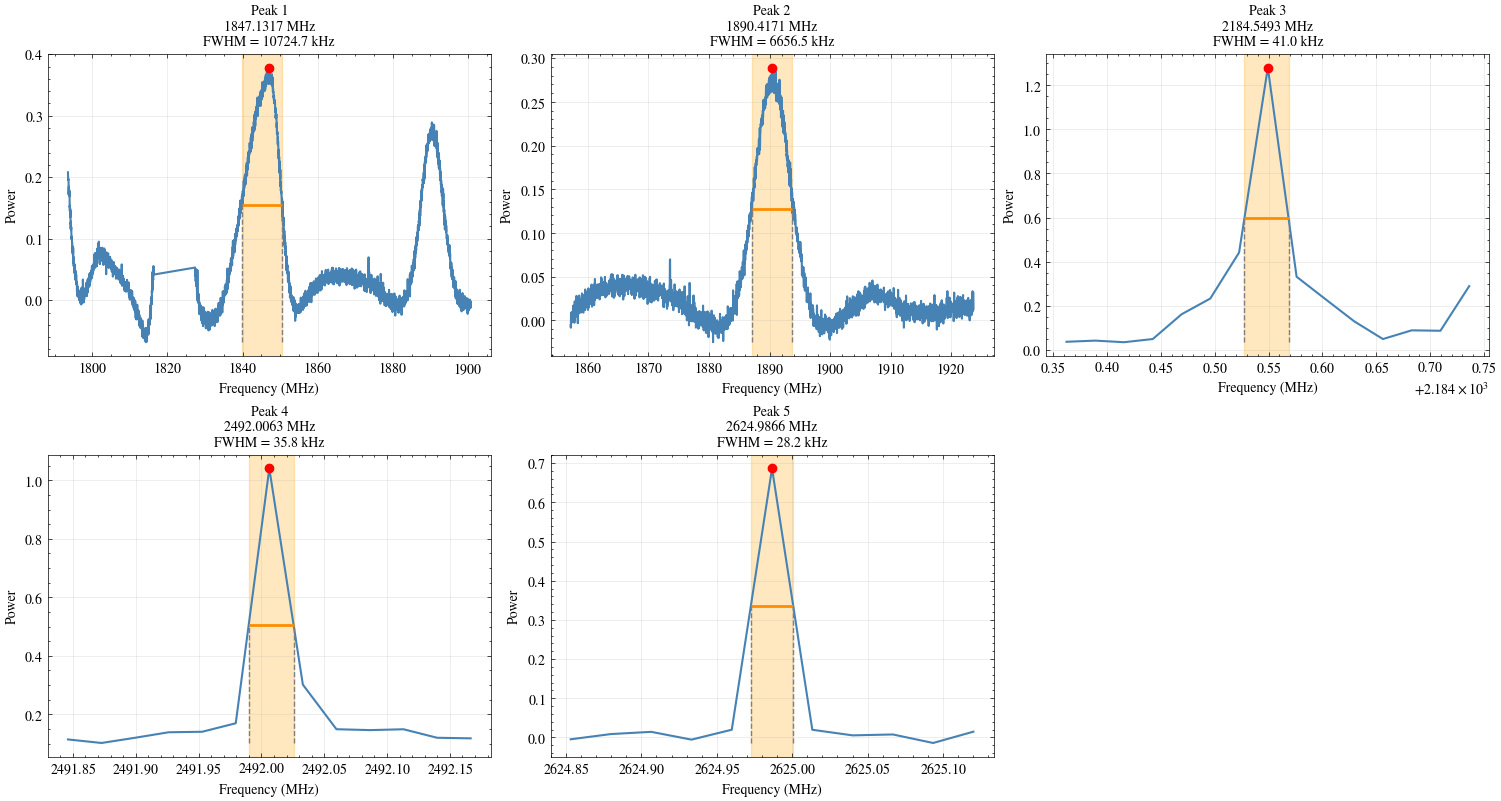

In [20]:
# Convert fractional index crossings to frequency values
idx_axis_low = np.arange(len(mask_frequency))
left_freq_low = np.interp(left_ips_low, idx_axis_low, mask_frequency)
right_freq_low = np.interp(right_ips_low, idx_axis_low, mask_frequency)
 

# ---------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side of the peak

n_peaks_low = len(peaks_low)

ncols = 3
nrows = math.ceil(n_peaks_low / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5*ncols, 4*nrows),
    constrained_layout=True
)

axes_low = np.atleast_1d(axes).flatten()

for i, peak in enumerate(peaks_low):

    ax = axes_low[i]

    centre = mask_frequency[peak]

    # Zoom window proportional to the measured FWHM
    x_min = centre - window * fwhm_freq_low[i]
    x_max = centre + window * fwhm_freq_low[i]

    mask = (mask_frequency >= x_min) & (mask_frequency <= x_max)

    # Spectrum
    ax.plot(
        mask_frequency[mask],
        mask_signal[mask],
        color="steelblue",
        lw=1.5
    )

    # Peak marker
    ax.plot(
        centre,
        mask_signal[peak],
        'ro',
        ms=6,
        label='Peak'
    )

    # FWHM line
    ax.hlines(
        width_heights_low[i],
        left_freq_low[i],
        right_freq_low[i],
        color='darkorange',
        lw=2,
        label='FWHM'
    )

    # Crossing points
    ax.vlines(
        [left_freq_low[i], right_freq_low[i]],
        ymin=mask_signal[mask].min(),
        ymax=width_heights_low[i],
        color='gray',
        linestyle='--'
    )

    # Shade the FWHM
    ax.axvspan(
        left_freq_low[i],
        right_freq_low[i],
        color='orange',
        alpha=0.25
    )

    ax.set_title(
        f"Peak {i+1}\n"
        f"{centre:.4f} MHz\n"
        f"FWHM = {fwhm_freq_low[i]*1000:.1f} kHz",
        fontsize=10
    )

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Power")
    ax.grid(alpha=0.3)

# Remove empty axes
for j in range(i + 1, len(axes_low)):
    fig.delaxes(axes_low[j])

plt.show()

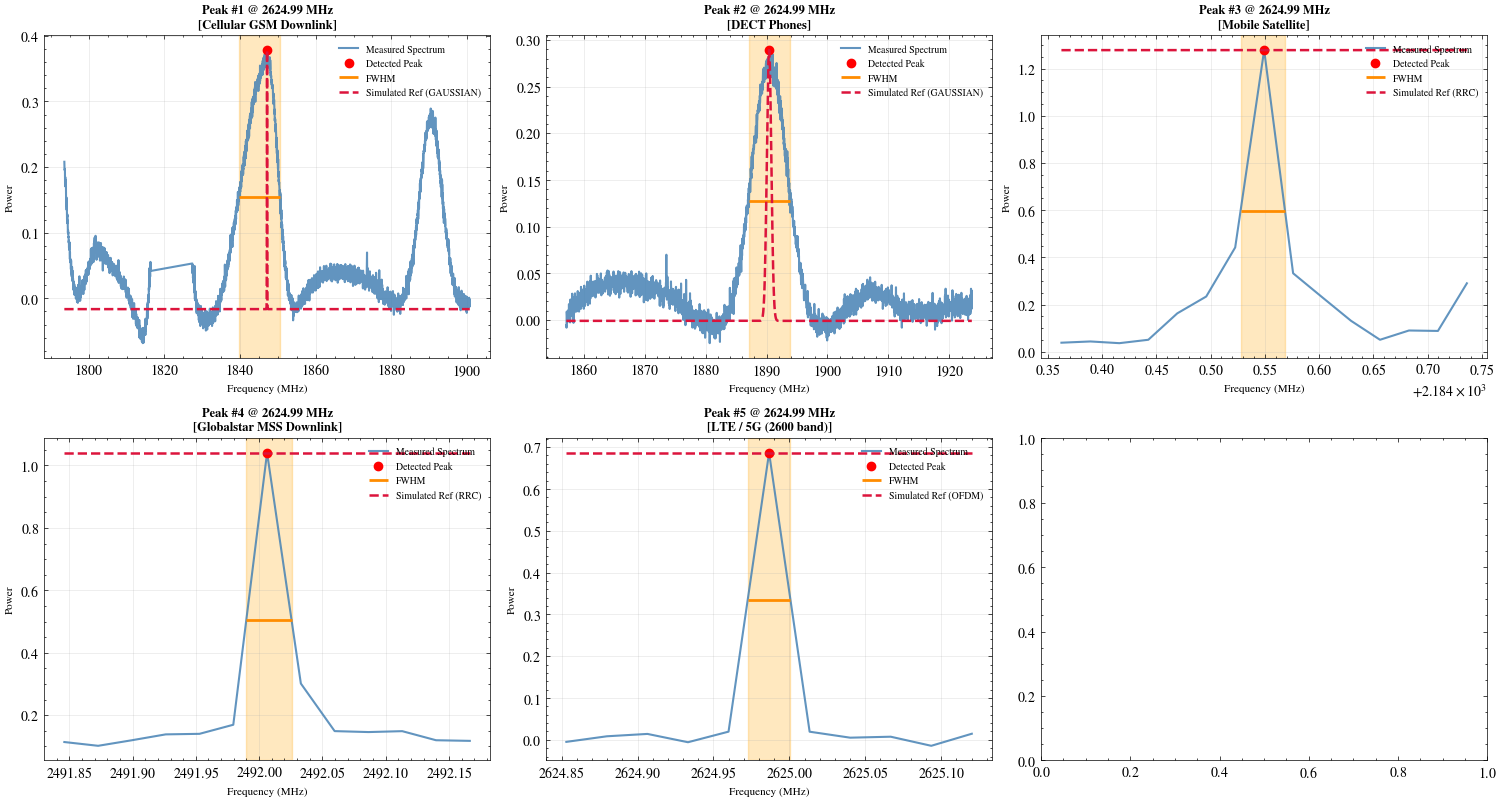

In [21]:
n_peaks_low = len(peaks_low)

ncols = 3
nrows = math.ceil(n_peaks_low / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5*ncols, 4*nrows),
    constrained_layout=True
)

axes_low = np.atleast_1d(axes).flatten()

for i, peak in enumerate(peaks_low):
    ax = axes_low[i]
    centre_low = mask_frequency[peak]
    fwhm_val = fwhm_freq_low[i]

    # Zoom window proportional to measured FWHM
    x_min = centre_low - window * fwhm_val
    x_max = centre_low + window * fwhm_val

    mask = (mask_frequency >= x_min) & (mask_frequency <= x_max)
    x_data = mask_frequency[mask]
    y_data = mask_signal[mask]

    # 1. Plot Measured Spectrum
    ax.plot(
        x_data,
        y_data,
        color="steelblue",
        lw=1.5,
        alpha=0.85,
        label="Measured Spectrum",
    )
    # Spectrum
    peak_amplitude = mask_signal[peak]
    ax.plot(centre_low, peak_amplitude, "ro", ms=6, label="Detected Peak")

        # FWHM line
    ax.hlines(
        width_heights_low[i],
        left_freq_low[i],
        right_freq_low[i],
        color='darkorange',
        lw=2,
        label='FWHM'
    )

       # Shade the FWHM
    ax.axvspan(
        left_freq_low[i],
        right_freq_low[i],
        color='orange',
        alpha=0.25
    )

    # 3. Lookup & Generate Simulated Target Signal Overlay
    sys_name, sys_specs = find_matching_system(centre_low)

    if sys_specs is not None:
        obw_nom = sys_specs["obw"]
        eta_nom = sys_specs["eta"]
        shape_type = sys_specs["type"]
    else:
        # Fallback to measured metrics if outside catalog
        obw_nom = fwhm_val * 2.0
        eta_nom = 2.0
        shape_type = "gaussian"

    # Generate normalized shape profile
    sim_shape = simulate_normalized_shape(
        x_data, centre_low, obw_nom, eta_nom, shape_type
    )

    # Scale simulated signal to match measured peak amplitude and baseline noise floor
    baseline_noise = np.percentile(y_data, 10)
    y_simulated = baseline_noise + (peak_amplitude - baseline_noise) * sim_shape

    # 4. Plot Simulated Reference Signal
    ax.plot(
        x_data,
        y_simulated,
        color="crimson",
        linestyle="--",
        lw=1.8,
        label=f"Simulated Ref ({shape_type.upper()})",
    )

    # Formatting and Annotations
    ax.set_title(
        f"Peak #{i+1} @ {centre:.2f} MHz\n[{sys_name}]",
        fontsize=9,
        fontweight="bold",
    )
    ax.set_xlabel("Frequency (MHz)", fontsize=8)
    ax.set_ylabel("Power", fontsize=8)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper right")

# Hide extra empty subplots if grid size > n_peaks
for j in range(n_peaks, len(axes_low)):
    fig.delaxes(axes_low[j])

plt.show()

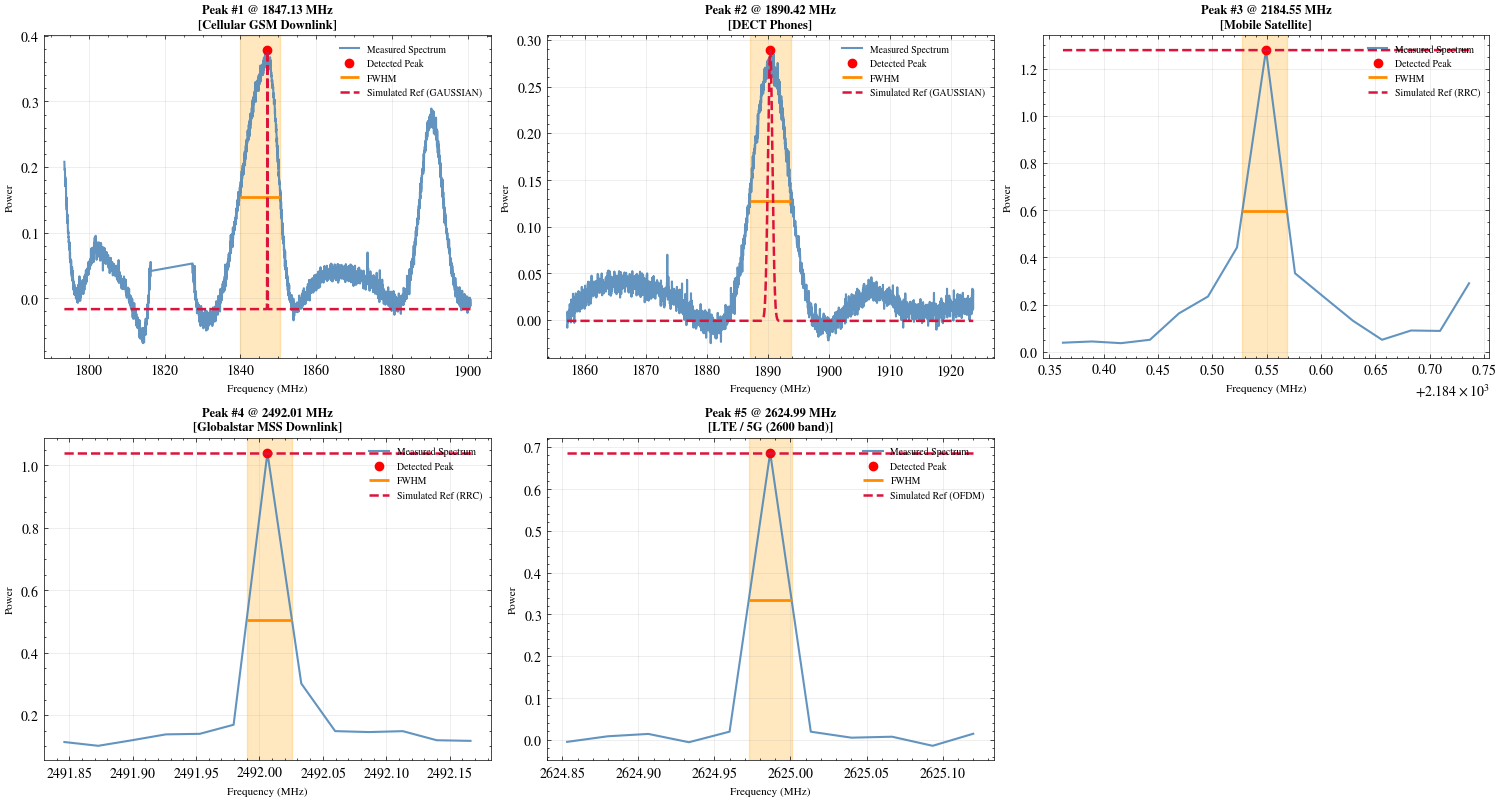

In [22]:

# ---------------------------------------------------------------
# Parameters & Grid Setup
# ---------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side of the peak
n_peaks_low = len(peaks_low)

ncols = 3
nrows = math.ceil(n_peaks_low / ncols)

fig, axes = plt.subplots(
    nrows, ncols, figsize=(5 * ncols, 4 * nrows), constrained_layout=True
)

axes_low = np.atleast_1d(axes).flatten()

for i, peak in enumerate(peaks_low):
    ax = axes_low[i]

    # Use centre_low consistently throughout
    centre_low = mask_frequency[peak]
    fwhm_val = fwhm_freq_low[i]

    # Zoom window proportional to measured FWHM
    x_min = centre_low - window * fwhm_val
    x_max = centre_low + window * fwhm_val

    mask = (mask_frequency >= x_min) & (mask_frequency <= x_max)
    x_data = mask_frequency[mask]
    y_data = mask_signal[mask]

    # 1. Plot Measured Spectrum
    ax.plot(
        x_data,
        y_data,
        color="steelblue",
        lw=1.5,
        alpha=0.85,
        label="Measured Spectrum",
    )

    # Peak marker
    peak_amplitude = mask_signal[peak]
    ax.plot(centre_low, peak_amplitude, "ro", ms=6, label="Detected Peak")

    # FWHM line
    ax.hlines(
        width_heights_low[i],
        left_freq_low[i],
        right_freq_low[i],
        color="darkorange",
        lw=2,
        label="FWHM",
    )

    # Shade the FWHM region
    ax.axvspan(
        left_freq_low[i], right_freq_low[i], color="orange", alpha=0.25
    )

    # 2. Lookup & Generate Simulated Target Signal Overlay
    sys_name, sys_specs = find_matching_system(centre_low)

    if sys_specs is not None:
        obw_nom = sys_specs["obw"]
        eta_nom = sys_specs["eta"]
        shape_type = sys_specs["type"]
    else:
        # Fallback to measured metrics if outside catalog
        obw_nom = fwhm_val * 2.0
        eta_nom = 2.0
        shape_type = "gaussian"

    # FIXED: Replaced 'centre' with 'centre_low'
    sim_shape = simulate_normalized_shape(
        x_data, centre_low, obw_nom, eta_nom, shape_type
    )

    # Scale simulated signal to match measured peak amplitude and baseline noise floor
    baseline_noise = np.percentile(y_data, 10)
    y_simulated = baseline_noise + (peak_amplitude - baseline_noise) * sim_shape

    # 3. Plot Simulated Reference Signal
    ax.plot(
        x_data,
        y_simulated,
        color="crimson",
        linestyle="--",
        lw=1.8,
        label=f"Simulated Ref ({shape_type.upper()})",
    )

    # Formatting and Annotations (FIXED: Replaced 'centre' with 'centre_low')
    ax.set_title(
        f"Peak #{i+1} @ {centre_low:.2f} MHz\n[{sys_name}]",
        fontsize=9,
        fontweight="bold",
    )
    ax.set_xlabel("Frequency (MHz)", fontsize=8)
    ax.set_ylabel("Power", fontsize=8)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper right")

# FIXED: Replaced 'n_peaks' with 'n_peaks_low'
for j in range(n_peaks_low, len(axes_low)):
    fig.delaxes(axes_low[j])

plt.show()

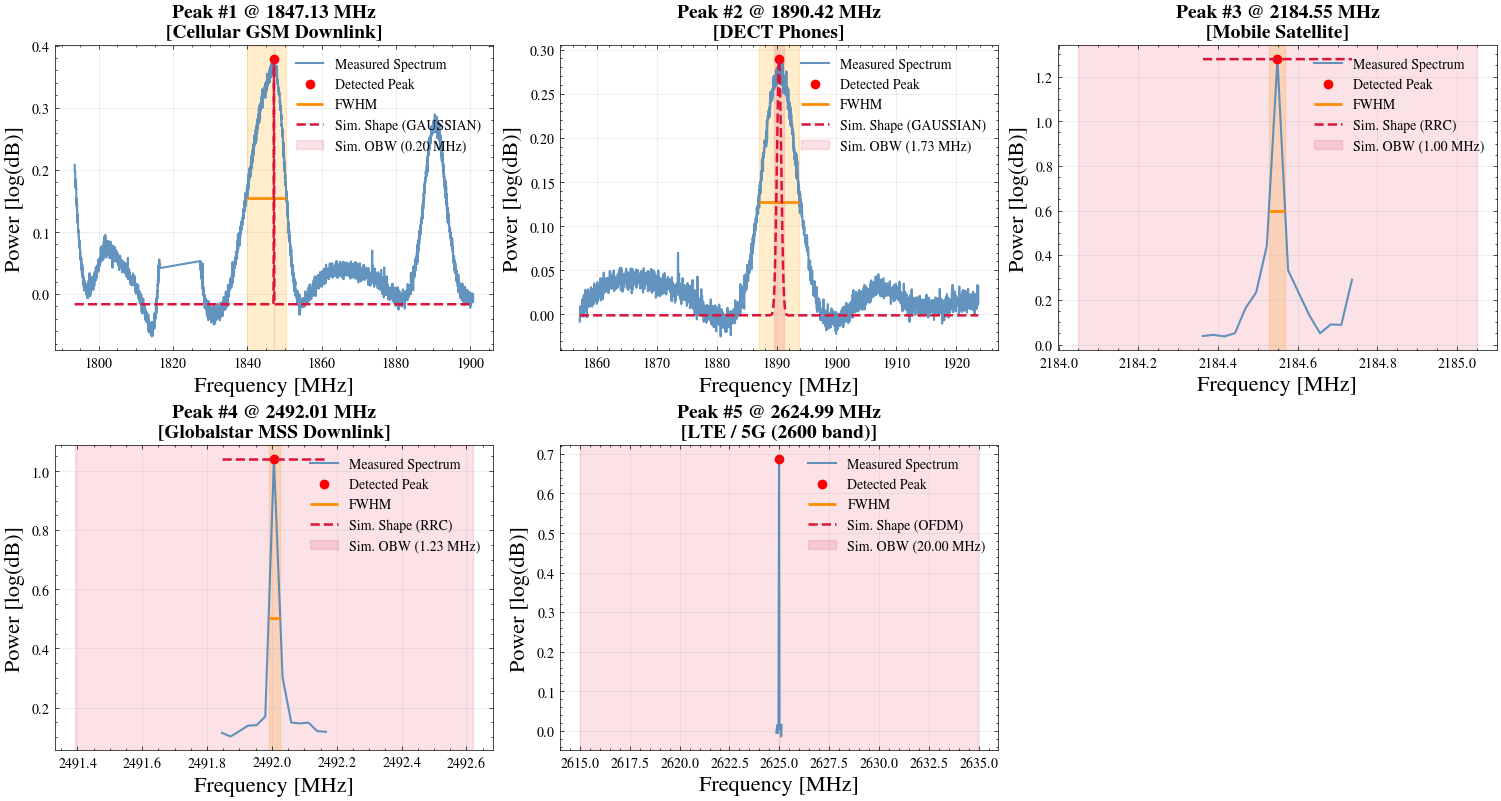

In [23]:

# -------------------------------------------------------------------
# 2. Parameters & Grid Visualization Setup
# -------------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side of peak
n_peaks_low = len(peaks_low)

ncols = 3
nrows = math.ceil(n_peaks_low / ncols)

fig, axes = plt.subplots(
    nrows, ncols, figsize=(5 * ncols, 4 * nrows), constrained_layout=True
)

axes_low = np.atleast_1d(axes).flatten()

for i, peak in enumerate(peaks_low):
    ax = axes_low[i]

    centre_low = mask_frequency[peak]
    fwhm_val = fwhm_freq_low[i]

    # Zoom window proportional to measured FWHM
    x_min = centre_low - window * fwhm_val
    x_max = centre_low + window * fwhm_val

    mask = (mask_frequency >= x_min) & (mask_frequency <= x_max)
    x_data = mask_frequency[mask]
    y_data = mask_signal[mask]

    # -------------------------------------------------------
    # A. Plot Measured Spectrum & FWHM Shading
    # -------------------------------------------------------
    ax.plot(
        x_data,
        y_data,
        color="steelblue",
        lw=1.5,
        alpha=0.85,
        label="Measured Spectrum",
    )

    # Peak marker
    peak_amplitude = mask_signal[peak]
    ax.plot(centre_low, peak_amplitude, "ro", ms=6, label="Detected Peak")

    # FWHM line
    ax.hlines(
        width_heights_low[i],
        left_freq_low[i],
        right_freq_low[i],
        color="darkorange",
        lw=2,
        label="FWHM",
    )

    # Shade Measured FWHM (Orange)
    ax.axvspan(
        left_freq_low[i], right_freq_low[i], color="orange", alpha=0.20
    )

    # -------------------------------------------------------
    # B. Lookup Catalog & Generate Simulated Overlay
    # -------------------------------------------------------
    sys_name, sys_specs = find_matching_system(centre_low)

    if sys_specs is not None:
        obw_nom = sys_specs["obw"]
        eta_nom = sys_specs["eta"]
        shape_type = sys_specs["type"]
    else:
        obw_nom = fwhm_val * 2.0
        eta_nom = 2.0
        shape_type = "gaussian"

    # Generate normalized shape profile
    sim_shape = simulate_normalized_shape(
        x_data, centre_low, obw_nom, eta_nom, shape_type
    )

    # Scale simulated signal to peak amplitude & baseline noise floor
    baseline_noise = np.percentile(y_data, 10)
    y_simulated = baseline_noise + (peak_amplitude - baseline_noise) * sim_shape

    # -------------------------------------------------------
    # C. Plot Simulated Signal & Shade Simulated OBW
    # -------------------------------------------------------
    ax.plot(
        x_data,
        y_simulated,
        color="crimson",
        linestyle="--",
        lw=1.8,
        label=f"Sim. Shape ({shape_type.upper()})",
    )

    # Shade Simulated Occupied Bandwidth (Crimson)
    ax.axvspan(
        centre_low - obw_nom / 2.0,
        centre_low + obw_nom / 2.0,
        color="crimson",
        alpha=0.12,
        label=f"Sim. OBW ({obw_nom:.2f} MHz)",
    )

    # -------------------------------------------------------
    # Subplot Formatting
    # -------------------------------------------------------
    ax.set_title(
        f"Peak #{i+1} @ {centre_low:.2f} MHz\n[{sys_name}]",
        fontsize=14,
        fontweight="bold",
    )
    ax.set_xlabel("Frequency [MHz]", fontsize=16)
    ax.set_ylabel("Power [log(dB)]", fontsize=16)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=10, loc="upper right")

# -------------------------------------------------------------------
# 3. Clean Up Extra Subplots & Render Figure
# -------------------------------------------------------------------
for j in range(n_peaks_low, len(axes_low)):
    fig.delaxes(axes_low[j])

if to_save:
        # create full path
    full_path = os.path.join(dirname, scan_name)
    # create the directory if they don't exist
    os.makedirs(full_path, exist_ok=True)

    fig.savefig(
        os.path.join(full_path, f'{scan_name}_low_peak_signal_fits.png'),
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        os.path.join(full_path, f'{scan_name}_low_peak_signal_fits.pdf'),
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()